# N8 — Is border destruction causal?

N7 showed that for the published decoder, errors on cells it can still see rise from 0.085 to
0.223 as the occluder brightens (r = +0.985), while the marker's border mean climbs 27.3 -> 135.4.
That is a **correlation**. Brighter occluders destroy the border, but they also change other
things, so it does not yet establish cause.

### The design

A marker is an 8x8 cell grid: a 1-cell black border ring around 6x6 data cells. Those two regions
can be occluded independently, which gives a clean 2x2:

| condition | border | data cells hidden |
|---|---|---|
| **clean** | intact | 0 |
| **border-only** | destroyed | **0** |
| **data-only** | intact | ~18 |
| **both** | destroyed | ~18 (this is N7's condition) |

**border-only is the decisive cell.** No data cell is hidden, so every one of the 36 bits is
visible. If error still rises with occluder intensity there, nothing but border destruction can
explain it — there is no hidden information to blame.

**data-only is the control.** Same number of hidden cells as N7, but the border survives. If error
stays flat in intensity here, that completes the argument.

### Predictions

| mechanism | border-only | data-only |
|---|---|---|
| border destruction is causal | error **rises** with intensity | error **flat** |
| something else | error flat | error rises |

Self-contained: run top to bottom in a fresh runtime. Set `RUN_ON` in cell 1 to `'dev'` or
`'heldout'`.

## 1. Bootstrap

Includes the h5py fix — newer h5py chokes on a dangling `input_1` link while walking the Keras
file, so the walk skips broken links and reads only `model_weights`. Shape assertions confirm the
real conv kernels and the per-element PReLU alphas were found.

In [9]:
RUN_ON = 'heldout'          # 'dev' = video_1..5   |   'heldout' = video_6 only

import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, torch, h5py
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
drive.mount('/content/drive')

BASE  = '/content/drive/MyDrive/aruco_p2'
ART, WORK, CACHE = f'{BASE}/artifacts', '/content/work', f'{BASE}/archives'
os.makedirs(WORK, exist_ok=True)

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1',
                    'https://github.com/AVAuco/deeparuco.git', REPO], check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits

def load_weights_safe(h5_path):
    store = {}
    with h5py.File(h5_path, 'r') as f:
        root = f['model_weights'] if 'model_weights' in f else f
        def walk(g, prefix=''):
            for k in g.keys():
                try: obj = g[k]
                except (KeyError, OSError): continue
                p = f'{prefix}/{k}'
                if isinstance(obj, h5py.Dataset): store[p] = np.array(obj)
                elif isinstance(obj, h5py.Group): walk(obj, p)
        walk(root)
    def pick(layer, suf):
        hits = [k for k in store if f'/{layer}/' in k and k.endswith(suf)]
        assert len(hits) == 1, f'{layer}:{suf} -> {hits}'
        return store[hits[0]]
    w = {'c1_w': pick('conv2d','kernel:0'),   'c1_b': pick('conv2d','bias:0'),
         'p1_a': pick('p_re_lu','alpha:0'),
         'c2_w': pick('conv2d_1','kernel:0'), 'c2_b': pick('conv2d_1','bias:0'),
         'p2_a': pick('p_re_lu_1','alpha:0'),
         'c3_w': pick('conv2d_2','kernel:0'), 'c3_b': pick('conv2d_2','bias:0')}
    for k, s in {'c1_w':(5,5,1,8),'c1_b':(8,),'p1_a':(28,28,8),'c2_w':(3,3,8,4),
                 'c2_b':(4,),'p2_a':(12,12,4),'c3_w':(1,1,4,1),'c3_b':(1,)}.items():
        assert w[k].shape == s, f'{k}: {w[k].shape} != {s}'
    return w

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
splits = json.load(open(f'{ART}/splits.json'))
VIEWS = splits['dev'] if RUN_ON == 'dev' else [splits['heldout'][0]]
STRIDE = splits['benchmark_stride']
Wk  = load_weights_safe(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
print(f'RUN_ON = {RUN_ON} -> viewpoints {VIEWS} | device {DEV_}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RUN_ON = heldout -> viewpoints ['video_6'] | device cpu


## 2. Pipeline

In [10]:
r_int = lambda v: int(round(v))

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]
def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))
def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)
def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out
def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max()-crop.min()+1e-9)
    nc = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)
def strip_box(img, corners, level, key, mid):
    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    side = int(np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode())).integers(0,4))
    box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
           (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    return (a,b,c,d) if (c>a and d>b) else None
def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out

class SpatialPReLU(nn.Module):
    def __init__(s,c,h,w): super().__init__(); s.a = nn.Parameter(torch.zeros(c,h,w))
    def forward(s,x): return torch.where(x>0, x, s.a.unsqueeze(0)*x)
class Decoder(nn.Module):
    def __init__(s, out_ch=1):
        super().__init__()
        s.c1=nn.Conv2d(1,8,5); s.p1=SpatialPReLU(8,28,28)
        s.c2=nn.Conv2d(8,4,3); s.p2=SpatialPReLU(4,12,12)
        s.c3=nn.Conv2d(4,out_ch,1); s.out_ch=out_ch
    def forward(s,x):
        x=F.max_pool2d(s.p1(s.c1(x)),2); x=F.max_pool2d(s.p2(s.c2(x)),2); x=s.c3(x)
        return (x[:,0], x[:,1]) if s.out_ch==2 else (x[:,0], None)

models = {}
for arm, oc, ck in [('B',1,f'{BASE}/ckpt_n3b/arm_B.pt'), ('E',1,f'{BASE}/ckpt_n6/arm_E.pt')]:
    if os.path.exists(ck):
        n = Decoder(oc).to(DEV_); n.load_state_dict(torch.load(ck, map_location=DEV_)); n.eval()
        models[arm] = n
    else:
        print(f'note: {ck} missing, arm {arm} skipped')

def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def decode_published(x8, chunk=4096):
    out=[]
    for s in range(0,len(x8),chunk):
        x = x8[s:s+chunk].astype(np.float32)[...,None]/255.0
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)
def decode_torch(net, x8, chunk=8192):
    ps=[]
    with torch.no_grad():
        for s in range(0,len(x8),chunk):
            xb = torch.tensor(x8[s:s+chunk], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            ps.append(torch.sigmoid(net(xb)[0]).cpu().numpy())
    return np.concatenate(ps)
def dec_soft(P):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)
print('pipeline ready | arms:', sorted(models))

pipeline ready | arms: ['B', 'E']


## 3. Border and data regions

GT corners mark the **outer** boundary of the black border. The marker is 8 cells across, so
shrinking the quad toward its centroid by 6/8 gives the inner boundary — everything between the
two quads is the border ring, everything inside is the 6x6 data region.

Occlusion is applied in the **source frame** so the region warps with perspective, exactly as in
every earlier experiment.

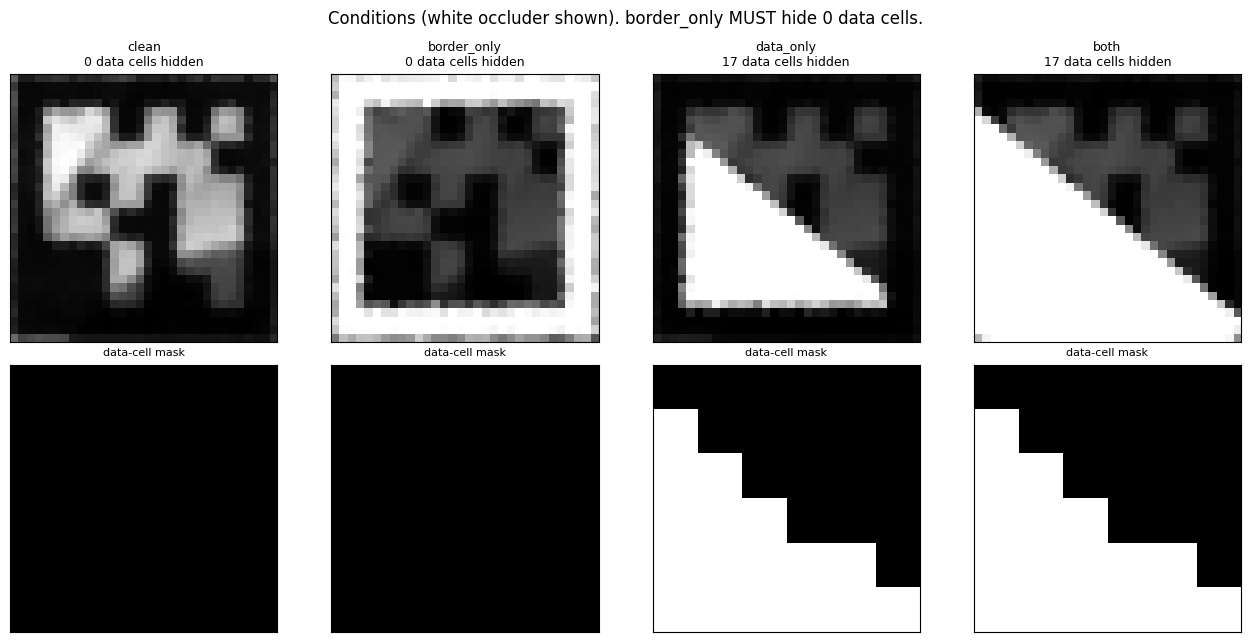

In [11]:
def region_masks(corners, shape):
    """Return (border_ring, data_region) binary masks in source-image coordinates."""
    c = corners.mean(axis=0)
    inner = c + (corners - c) * (6.0/8.0)
    m_out = np.zeros(shape, np.uint8); cv2.fillPoly(m_out, [corners.astype(np.int32)], 255)
    m_in  = np.zeros(shape, np.uint8); cv2.fillPoly(m_in,  [inner.astype(np.int32)], 255)
    return cv2.bitwise_and(m_out, cv2.bitwise_not(m_in)), m_in

def make_condition(img, corners, cond, value, key, mid, level=0.50):
    """Returns (occluded_image, occlusion_mask). Occlusion mask covers only what is painted."""
    if cond == 'clean':
        return img, np.zeros(img.shape[:2], np.uint8)
    border, data = region_masks(corners, img.shape[:2])
    if cond == 'border_only':
        paint = border
    else:
        box = strip_box(img, corners, level, key, mid)
        if box is None: return None, None
        a,b,c,d = box
        strip = np.zeros(img.shape[:2], np.uint8); strip[b:d, a:c] = 255
        paint = cv2.bitwise_and(strip, data) if cond == 'data_only' else strip
    out = img.copy(); out[paint > 0] = int(value)
    return out, paint

CONDS   = ['clean', 'border_only', 'data_only', 'both']
INTENS  = [0, 64, 127, 192, 255]

# --- visual check: confirm each condition covers what it claims ---
f, j = pairs_for(VIEWS[0])[0]
img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
mk  = json.load(open(j))['markers'][0]
cn  = get_corners(mk); key = 'viz'
fig, ax = plt.subplots(2, 4, figsize=(13, 6.5))
for i, cond in enumerate(CONDS):
    oi, om = make_condition(img, cn, cond, 255, key, int(mk['id']))
    x32, occ = prepare(oi, om, cn)
    ax[0,i].imshow(x32, cmap='gray'); ax[0,i].set_title(f'{cond}\n{occ.sum()} data cells hidden', fontsize=9)
    ax[1,i].imshow(occ, cmap='gray', interpolation='nearest')
    ax[1,i].set_title('data-cell mask', fontsize=8)
    for r in range(2): ax[r,i].set_xticks([]); ax[r,i].set_yticks([])
plt.suptitle('Conditions (white occluder shown). border_only MUST hide 0 data cells.')
plt.tight_layout(); plt.show()

## 4. Build all conditions

In [12]:
DATA = {(c,v): {'x':[], 'id':[], 'mask':[], 'frame':[]} for c in CONDS for v in INTENS}
t0 = time.time()
for vid in VIEWS:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for cond in CONDS:
                for v in INTENS:
                    oi, om = make_condition(img, cn, cond, v, key, mid)
                    if oi is None: continue
                    x32, occ = prepare(oi, om, cn)
                    if x32 is None: continue
                    d = DATA[(cond,v)]
                    d['x'].append((x32*255).astype(np.uint8)); d['id'].append(mid)
                    d['mask'].append(occ); d['frame'].append(key)
    print(f'  {vid} ({time.time()-t0:.0f}s)')
for k in DATA:
    for kk in DATA[k]: DATA[k][kk] = np.array(DATA[k][kk])

n = len(DATA[('clean',0)]['id'])
print(f'\n{n} markers per cell')
assert n > 2000, f'only {n} markers — data not loaded correctly'
print(f"{'condition':>13}" + ''.join(f'{v:>8}' for v in INTENS) + '   (mean data cells hidden)')
for cond in CONDS:
    print(f'{cond:>13}' + ''.join(f'{DATA[(cond,v)]["mask"].sum(axis=(1,2)).mean():>8.1f}' for v in INTENS))
assert DATA[('border_only',255)]['mask'].sum(axis=(1,2)).mean() < 0.5, \
    'border_only is hiding data cells — the inner quad is wrong'
print('\nborder_only hides ~0 data cells: the decisive condition is valid')

  video_6 (92s)

3456 markers per cell
    condition       0      64     127     192     255   (mean data cells hidden)
        clean     0.0     0.0     0.0     0.0     0.0
  border_only     0.0     0.0     0.0     0.0     0.0
    data_only    18.0    18.0    18.0    18.0    18.0
         both    18.0    18.0    18.0    18.0    18.0

border_only hides ~0 data cells: the decisive condition is valid


## 5. Evaluate

In [13]:
def true_bits_oriented(P, ids):
    obs = (P > 0.5).astype(np.uint8); out = np.empty_like(obs)
    for i in range(len(P)):
        ref = CB[ids[i]]; best, bk = 99, 0
        for k in range(4):
            h = int(np.sum(np.rot90(obs[i], k) != ref))
            if h < best: best, bk = h, k
        out[i] = np.rot90(ref, -bk)
    return out

ARMS = ['A'] + sorted(models)
R = {}
for cond in CONDS:
    for v in INTENS:
        d = DATA[(cond,v)]; R[(cond,v)] = {}
        for arm in ARMS:
            P = decode_published(d['x']) if arm=='A' else decode_torch(models[arm], d['x'])
            T = true_bits_oriented(P, d['id']); err = (obs := (P>0.5).astype(np.uint8)) != T
            M = d['mask']
            R[(cond,v)][arm] = {
                'acc':     float((dec_soft(P) == d['id']).mean()),
                'err_all': float(err.mean()),
                'err_vis': float(err[~M].mean()) if (~M).any() else np.nan,
                'border':  None}
    print(f'{cond} done')

def border_mean(x8, k=1500):
    s = 32/8.0; vals=[]
    for img in x8[:k]:
        vv=[img[int(r*s):int((r+1)*s), int(c*s):int((c+1)*s)].mean()
            for r in range(8) for c in range(8) if r in (0,7) or c in (0,7)]
        vals.append(np.mean(vv))
    return float(np.mean(vals))
for cond in CONDS:
    for v in INTENS:
        R[(cond,v)]['A']['border'] = border_mean(DATA[(cond,v)]['x'])
print('done')

clean done
border_only done
data_only done
both done
done


## 6. The decisive table

**border_only hides zero data cells.** Every bit is visible. If error rises with intensity there,
border destruction is causal — there is no hidden information left to blame.

In [14]:
for arm in ARMS:
    print(f'\n=== arm {arm} — error on VISIBLE cells ===')
    print(f"{'condition':>13}" + ''.join(f'{v:>9}' for v in INTENS) + f"{'slope':>10}{'r':>8}")
    print('-'*(13+9*len(INTENS)+18))
    for cond in CONDS:
        e = np.array([R[(cond,v)][arm]['err_vis'] for v in INTENS])
        x = np.array(INTENS, float)
        r = float(np.corrcoef(x, e)[0,1]) if np.std(e) > 1e-9 else 0.0
        print(f'{cond:>13}' + ''.join(f'{v:>9.3f}' for v in e)
              + f'{(e[-1]-e[0]):>10.3f}{r:>8.3f}')

print('\n=== ID accuracy ===')
for arm in ARMS:
    print(f'\narm {arm}')
    print(f"{'condition':>13}" + ''.join(f'{v:>9}' for v in INTENS))
    for cond in CONDS:
        print(f'{cond:>13}' + ''.join(f'{R[(cond,v)][arm]["acc"]:>9.1%}' for v in INTENS))

print('\n=== border mean in the rectified crop ===')
print(f"{'condition':>13}" + ''.join(f'{v:>9}' for v in INTENS))
for cond in CONDS:
    print(f'{cond:>13}' + ''.join(f'{R[(cond,v)]["A"]["border"]:>9.1f}' for v in INTENS))


=== arm A — error on VISIBLE cells ===
    condition        0       64      127      192      255     slope       r
----------------------------------------------------------------------------
        clean    0.031    0.031    0.031    0.031    0.031     0.000   0.000
  border_only    0.121    0.160    0.210    0.240    0.260     0.139   0.988
    data_only    0.114    0.145    0.186    0.217    0.238     0.124   0.994
         both    0.119    0.153    0.193    0.219    0.238     0.119   0.992

=== arm B — error on VISIBLE cells ===
    condition        0       64      127      192      255     slope       r
----------------------------------------------------------------------------
        clean    0.038    0.038    0.038    0.038    0.038     0.000   0.000
  border_only    0.155    0.079    0.100    0.116    0.135    -0.020  -0.009
    data_only    0.168    0.090    0.113    0.135    0.151    -0.017   0.062
         both    0.168    0.077    0.101    0.117    0.134    -0.034  -0.

## 7. Verdict

In [15]:
print('Predictions:')
print('  border destruction causal -> border_only RISES with intensity, data_only FLAT')
print('  something else            -> border_only FLAT\n')

verdict = {}
for arm in ARMS:
    b = np.array([R[('border_only',v)][arm]['err_vis'] for v in INTENS])
    d = np.array([R[('data_only',v)][arm]['err_vis'] for v in INTENS])
    o = np.array([R[('both',v)][arm]['err_vis'] for v in INTENS])
    verdict[arm] = (b[-1]-b[0], d[-1]-d[0], o[-1]-o[0])
    print(f'arm {arm}:')
    print(f'  border_only  rise: {b[-1]-b[0]:+.3f}   ({b[0]:.3f} -> {b[-1]:.3f})   ZERO data cells hidden')
    print(f'  data_only    rise: {d[-1]-d[0]:+.3f}   ({d[0]:.3f} -> {d[-1]:.3f})   border intact')
    print(f'  both (N7)    rise: {o[-1]-o[0]:+.3f}   ({o[0]:.3f} -> {o[-1]:.3f})')
    share = (b[-1]-b[0])/(o[-1]-o[0])*100 if abs(o[-1]-o[0]) > 1e-6 else float("nan")
    print(f'  border-only accounts for {share:.0f}% of the full effect\n')

bA, dA, oA = verdict['A']
if bA > 0.03 and bA > 2*max(dA, 0.0):
    print('CAUSAL. Destroying the border alone reproduces the effect with no data cells hidden.')
    print('The mechanism is border destruction pushing the crop out of distribution, not')
    print('loss of the covered bits.')
elif bA > 0.03:
    print('PARTIAL. Both regions contribute; report the decomposition rather than a single cause.')
else:
    print('NOT CAUSAL. Border destruction alone does not reproduce the effect.')
    print('The N7 correlation has another explanation — do not claim the border mechanism.')

json.dump({'run_on': RUN_ON, 'viewpoints': VIEWS, 'conditions': CONDS, 'intensities': INTENS,
           'n_markers': int(n),
           'results': {f'{c}_{v}_{a}': {k: (float(x) if x is not None else None)
                                        for k,x in R[(c,v)][a].items()}
                       for c in CONDS for v in INTENS for a in ARMS},
           'verdict': {a: [float(x) for x in verdict[a]] for a in ARMS}},
          open(f'{ART}/n8_border_causal_{RUN_ON}.json','w'), indent=1)
print(f'\nsaved -> {ART}/n8_border_causal_{RUN_ON}.json')

Predictions:
  border destruction causal -> border_only RISES with intensity, data_only FLAT
  something else            -> border_only FLAT

arm A:
  border_only  rise: +0.139   (0.121 -> 0.260)   ZERO data cells hidden
  data_only    rise: +0.124   (0.114 -> 0.238)   border intact
  both (N7)    rise: +0.119   (0.119 -> 0.238)
  border-only accounts for 117% of the full effect

arm B:
  border_only  rise: -0.020   (0.155 -> 0.135)   ZERO data cells hidden
  data_only    rise: -0.017   (0.168 -> 0.151)   border intact
  both (N7)    rise: -0.034   (0.168 -> 0.134)
  border-only accounts for 58% of the full effect

arm E:
  border_only  rise: -0.064   (0.173 -> 0.109)   ZERO data cells hidden
  data_only    rise: -0.021   (0.145 -> 0.124)   border intact
  both (N7)    rise: -0.027   (0.147 -> 0.119)
  border-only accounts for 234% of the full effect

PARTIAL. Both regions contribute; report the decomposition rather than a single cause.

saved -> /content/drive/MyDrive/aruco_p2/artifac

## 8. Figure

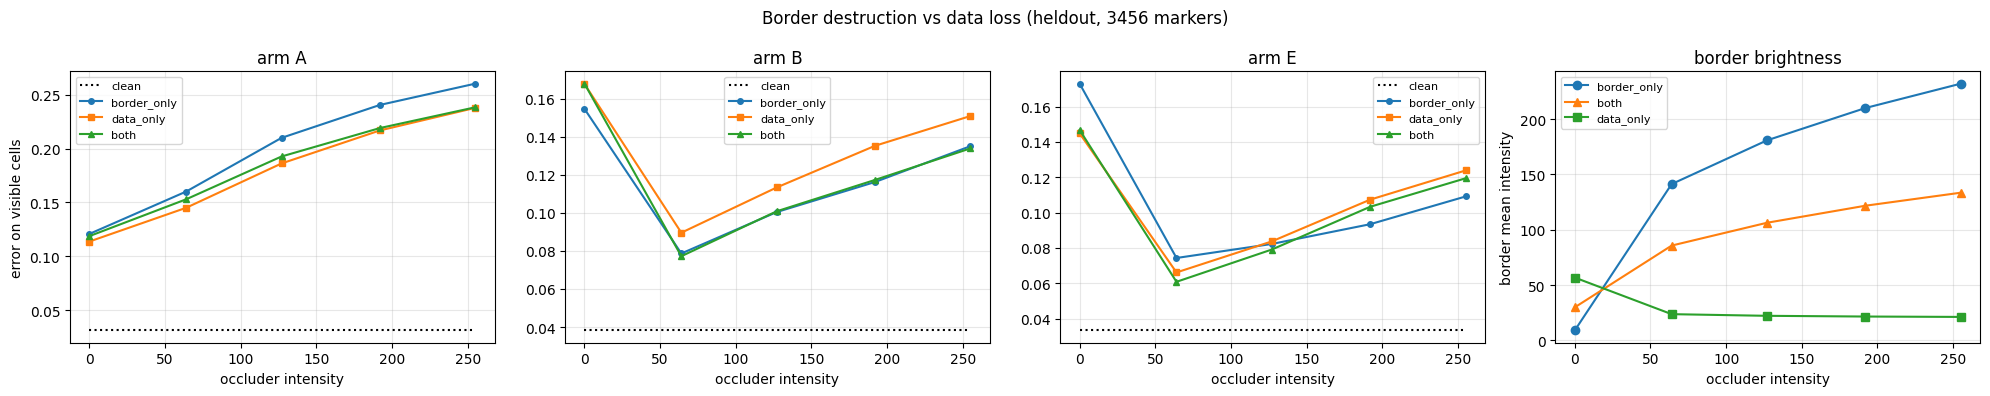

In [16]:
fig, ax = plt.subplots(1, len(ARMS)+1, figsize=(5*(len(ARMS)+1), 4))
for i, arm in enumerate(ARMS):
    for cond, st in [('clean','k:'),('border_only','-o'),('data_only','-s'),('both','-^')]:
        ax[i].plot(INTENS, [R[(cond,v)][arm]['err_vis'] for v in INTENS], st, ms=4, label=cond)
    ax[i].set_xlabel('occluder intensity'); ax[i].set_ylabel('error on visible cells' if i==0 else '')
    ax[i].set_title(f'arm {arm}'); ax[i].legend(fontsize=8); ax[i].grid(alpha=.3)
ax[-1].plot(INTENS, [R[('border_only',v)]['A']['border'] for v in INTENS], '-o', label='border_only')
ax[-1].plot(INTENS, [R[('both',v)]['A']['border'] for v in INTENS], '-^', label='both')
ax[-1].plot(INTENS, [R[('data_only',v)]['A']['border'] for v in INTENS], '-s', label='data_only')
ax[-1].set_xlabel('occluder intensity'); ax[-1].set_ylabel('border mean intensity')
ax[-1].set_title('border brightness'); ax[-1].legend(fontsize=8); ax[-1].grid(alpha=.3)
plt.suptitle(f'Border destruction vs data loss ({RUN_ON}, {n} markers)')
plt.tight_layout(); plt.show()